# FIAP · Fase 6 · PBL "O despertar da Rede Neural"

**Aluno:** Willian Kauê Tobias do Carmo · **RM:** 570038 · **Grupo 64** · Tecnologia em Inteligência Artificial
**Cliente fictício:** FarmTech Solutions · **Caso de uso:** controle de acesso com verificação de EPI

## Contexto

A FarmTech Solutions expandiu seus serviços de IA para segurança patrimonial e controle de acesso de funcionários. Este notebook demonstra, para um cliente, um sistema de visão computacional que detecta dois objetos relevantes na portaria de uma área operacional:

- **capacete**: EPI obrigatório para entrar na área;
- **celular**: item restrito em determinadas áreas.

A escolha do par tem um motivo técnico além do narrativo: *celular* existe no dataset COCO (classe `cell phone`) e *capacete* não existe. Isso permite, na Entrega 2, medir o que uma YOLO padrão (pré-treinada no COCO) faz com cada classe e mostrar em que situação a customização da rede é indispensável.

## Como executar

1. Runtime → Change runtime type → **T4 GPU**.
2. **Com Google Drive** (`USAR_DRIVE = True`): o notebook monta o Drive e usa a pasta `MyDrive/fiap_fase6/`, onde ficam o dataset, os rótulos do Make Sense e os resultados dos treinos.
3. **Sem Google Drive** (ex.: correção): o notebook obtém o dataset e os rótulos do próprio repositório do GitHub, sem nenhuma configuração.
4. Execute as células em ordem (Runtime → Run all). Os dois treinos levam poucos minutos em GPU.

> **Sobre esta execução:** as saídas gravadas neste notebook vieram de uma execução em **CPU** (Linux, 2 núcleos, sem GPU), fora do Colab. O código é o mesmo; a diferença é o tempo de treino, cerca de 10 vezes maior do que em uma T4. Os tempos reportados nas tabelas refletem esse ambiente.

## Sumário

1. Setup · 2. Dataset · 3. Rotulação no Make Sense · 4. Treinamento YOLOv5 (30 vs 60 épocas) · 5. Validação e teste · 6. Inferência nas imagens de teste · 7. Conclusões da Entrega 1 · 8. Entrega 2: YOLO padrão e CNN do zero · 9. Comparação crítica das três abordagens · 10. Conclusão geral · Apêndice: reprodutibilidade do dataset · Referências

## 1. Setup

Todos os parâmetros do projeto ficam na célula abaixo. O restante do notebook deriva deles, então trocar o par de objetos, o número de épocas ou o tamanho de imagem é uma edição em um único lugar.

In [1]:
# ============================================================
# PARÂMETROS DO PROJETO (único lugar que precisa ser editado)
# ============================================================
ALUNO = "Willian Kauê Tobias do Carmo"
RM = "570038"
GRUPO = "Grupo 64"
REPO_GITHUB = "https://github.com/willktdc/grupo64-fiap-fase6"   # <- confirmar o nome do repositório

# Classes do detector: nome interno (usado nos rótulos) -> nome da classe no Open Images.
# A ORDEM define o índice da classe (0 = celular, 1 = capacete). Use a mesma ordem ao criar as labels no Make Sense.
CLASSES = {"celular": "Mobile phone", "capacete": "Helmet"}
NOMES = list(CLASSES)

IMG = 640            # resolução de treino/inferência da YOLO
BATCH = 8              # cabe em CPU e em qualquer GPU do Colab
SEED = 0             # mesma semente nos dois treinos, para a comparação ser justa
EPOCAS = [30, 60]    # as duas simulações exigidas pelo enunciado (valores bem diferentes entre si)
CONF = 0.25          # confiança mínima para exibir uma detecção

USAR_DRIVE = True    # False para rodar sem Google Drive (o notebook baixa tudo do GitHub)

In [2]:
# Bibliotecas de uso geral. As específicas (YOLOv5, TensorFlow) são carregadas nas seções em que entram.
import os, sys, re, time, json, shutil, zipfile, subprocess, random, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)

# Confirma a GPU: sem ela o treino funciona, mas leva muito mais tempo.
!nvidia-smi -L || echo "ATENÇÃO: sem GPU. Vá em Runtime > Change runtime type > T4 GPU"

/bin/bash: line 1: nvidia-smi: command not found
ATENÇÃO: sem GPU. Vá em Runtime > Change runtime type > T4 GPU


In [3]:
# Pasta base: Google Drive (persistente entre sessões) ou pasta local (correção / execução sem Drive).
BASE = None
if USAR_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = Path("/content/drive/MyDrive/fiap_fase6")
    except Exception as e:                      # fora do Colab ou autorização negada
        print("Drive indisponível, usando pasta local. Motivo:", e)
if BASE is None:
    BASE = Path("/content/fiap_fase6")
BASE.mkdir(parents=True, exist_ok=True)

DATASET = BASE / "dataset"          # imagens, rótulos, manifesto, créditos
RUNS = BASE / "runs"                # resultados dos treinos (equivalente ao yolov5/runs, mas persistido)
RESULTADOS = BASE / "results"       # figuras e prints usados no README
LOCAL = Path("/content/dataset")    # cópia local do dataset (I/O do Drive é lento para treinar)
for p in (RUNS, RESULTADOS): p.mkdir(parents=True, exist_ok=True)
print("Pasta base:", BASE)

Drive indisponível, usando pasta local. Motivo: No module named 'google.colab'
Pasta base: /content/fiap_fase6


## 2. Dataset

### Fonte e critérios de seleção

As 80 imagens são um **subconjunto curado do [Open Images V7](https://storage.googleapis.com/openimages/web/index.html)** (Google), um dataset de fotos reais do Flickr publicadas sob licença Creative Commons (todas as imagens usadas aqui são CC BY 2.0; autor e link de cada uma estão em `dataset/CREDITOS.md`). A fonte foi escolhida por três razões:

1. **Realismo**: são fotos de pessoas comuns, com variação de ambiente, luz, ângulo e aparelho, bem diferente de fotos de estúdio ou de um único ambiente doméstico;
2. **Reprodutibilidade**: qualquer pessoa consegue recriar exatamente o mesmo dataset a partir dos IDs listados em `dataset/manifesto.csv` (ver Apêndice);
3. **Escala**: o filtro abaixo foi aplicado sobre ~1,7 mil imagens candidatas das duas classes, e as 80 finais foram escolhidas por inspeção visual.

Filtro automático aplicado às anotações oficiais (splits `validation` e `test` do Open Images):

| Critério | Motivo |
|---|---|
| Exatamente **uma** caixa da classe na imagem | uma classe por foto, exigência da CNN de classificação da Entrega 2 |
| Caixa ocupando **≥ 12%** da imagem | objeto visível, como numa foto apontada para ele |
| Sem `IsGroupOf`, `IsDepiction`, `IsInside` | nada de multidões, desenhos ou interiores |
| Imagem **não contém a outra classe** (nem parentes: *Bicycle helmet*, *Football helmet*, *Telephone*) | evita ambiguidade nos rótulos |
| Rotação EXIF conhecida e igual a 0 | para as caixas oficiais baterem com os pixels |

Na inspeção visual foram descartadas réplicas de museu, máscaras, adereços de fantasia, renders de produto, telefones sem fio e brinquedos, deixando um conjunto com **mistura deliberada de escalas**: metade com o objeto em close e metade com o objeto em contexto (na cabeça de um operário, na mão de uma pessoa).

### Organização

- Split **estratificado por classe**, com semente fixa: 32 treino / 4 validação / 4 teste para cada classe (64 / 8 / 8 no total), conforme o enunciado;
- Imagens redimensionadas para no máximo 1024 px no maior lado, sem distorção;
- Estrutura no Google Drive (`MyDrive/fiap_fase6/dataset/`), no padrão esperado pela YOLOv5:

```
dataset/
├── images/{train,val,test}/        celular_001.jpg … capacete_040.jpg
├── labels/{train,val,test}/        rótulos criados no Make Sense (seção 3)
├── gabarito_openimages/{...}/      caixas oficiais do Open Images, usadas só para conferir a rotulação
├── manifesto.csv                   arquivo, classe, split, ID no Open Images, caixa oficial, autor, licença
└── CREDITOS.md                     atribuição imagem a imagem
```

In [4]:
# Obtém o dataset, nesta ordem: (1) já está na pasta base; (2) zip na pasta base; (3) clone do repositório do GitHub.
def dataset_ok(p):
    return len(list((p / "images" / "train").glob("*.jpg"))) == 64 and (p / "manifesto.csv").exists()

if not dataset_ok(DATASET):
    z = BASE / "dataset_fase6.zip"
    if z.exists():
        print("Extraindo", z.name)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATASET)
    else:
        print("Baixando o dataset do repositório:", REPO_GITHUB)
        tmp = Path("/content/repo_tmp"); shutil.rmtree(tmp, ignore_errors=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_GITHUB, str(tmp)], check=True)
        shutil.copytree(tmp / "dataset", DATASET, dirs_exist_ok=True)
assert dataset_ok(DATASET), "Dataset não encontrado: coloque dataset_fase6.zip em " + str(BASE)

manifesto = pd.read_csv(DATASET / "manifesto.csv")
print("Imagens por classe e split:")
display(manifesto.groupby(["classe", "split"]).size().unstack())
print("Licenças:", manifesto.licenca.value_counts().to_dict())

Extraindo dataset_fase6.zip


Imagens por classe e split:


split,test,train,val
classe,,,
capacete,4,32,4
celular,4,32,4


Licenças: {'https://creativecommons.org/licenses/by/2.0/': 80}


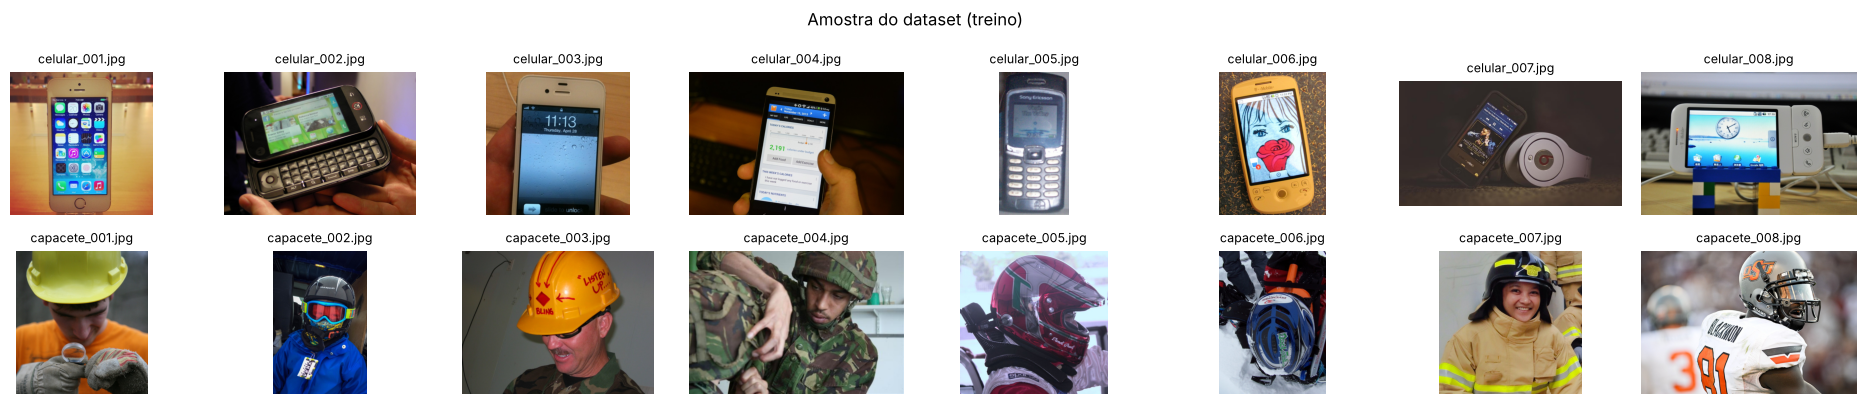

In [5]:
# Amostra do dataset: 8 imagens de treino de cada classe, para dar uma ideia da variedade.
def mostrar_grade(caminhos, titulos=None, cols=4, tam=3.4, titulo=None, salvar=None):
    """Exibe uma grade de imagens (e opcionalmente salva a figura em RESULTADOS)."""
    caminhos = [Path(c) for c in caminhos]
    titulos = titulos or [c.name for c in caminhos]
    linhas = (len(caminhos) + cols - 1) // cols
    fig, eixos = plt.subplots(linhas, cols, figsize=(cols * tam, linhas * tam * 0.85))
    eixos = np.array(eixos).ravel()
    for eixo, c, t in zip(eixos, caminhos, titulos):
        eixo.imshow(Image.open(c)); eixo.set_title(t, fontsize=9); eixo.axis("off")
    for eixo in eixos[len(caminhos):]:
        eixo.axis("off")
    if titulo: fig.suptitle(titulo, fontsize=12)
    plt.tight_layout()
    if salvar: fig.savefig(RESULTADOS / salvar, dpi=110, bbox_inches="tight")
    plt.show()

amostra = [DATASET / "images/train" / a for a in manifesto[manifesto.split == "train"].groupby("classe").head(8).arquivo]
mostrar_grade(amostra, cols=8, tam=2.4, titulo="Amostra do dataset (treino)", salvar="amostra_dataset.png")

## 3. Rotulação no Make Sense

A rotulação foi feita no [Make Sense](https://www.makesense.ai), conforme o enunciado, para **todas as 80 imagens** (e não só as de treino): a YOLOv5 precisa dos rótulos de validação para calcular mAP a cada época, e os de teste permitem medir o desempenho final no conjunto que o modelo nunca viu.

Como cada imagem já vem com uma caixa anotada por profissionais no Open Images, adotei um fluxo de **importar, revisar e exportar** em vez de desenhar as 80 caixas do zero. É o mesmo fluxo usado em projetos reais quando existe uma pré-anotação (de um modelo ou de outra fonte): a ferramenta serve para conferir e corrigir, e o rótulo final é o que sai dela.

Passo a passo executado:

1. `makesense.ai` → *Get Started* → carregar as 80 imagens (`images/train`, `val` e `test`) → *Object Detection*;
2. *Load labels from file* com um `labels.txt` contendo `celular` e `capacete`, **nesta ordem** (a ordem vira o índice da classe no formato YOLO e precisa bater com `NOMES`);
3. *Actions → Import Annotations → Multiple files in YOLO format*: as 80 caixas de origem (`gabarito_openimages/`, já no formato YOLO) mais o `labels.txt`. Detalhe prático: o Make Sense só associa anotações a imagens já carregadas na lista lateral, então foi preciso percorrer toda a lista de miniaturas antes da importação (na primeira tentativa, apenas as 24 imagens visíveis receberam caixas);
4. Revisão visual das caixas na ferramenta. A maioria está justa ao objeto; em alguns capacetes de perfil (ex.: `capacete_004`) a caixa de origem é folgada e inclui parte do rosto. Mantive as caixas como estavam para preservar a consistência com o critério de anotação do Open Images, e registro isso como limitação;
5. *Actions → Export Annotations → A .zip package containing files in YOLO format*, salvo em `MyDrive/fiap_fase6/makesense/` (qualquer nome terminado em `.zip`; todos os zips da pasta são lidos).

Formato YOLO gerado pelo Make Sense: um `.txt` por imagem, com uma linha por caixa `classe x_centro y_centro largura altura`, tudo normalizado entre 0 e 1.

A célula seguinte distribui os `.txt` exportados nas pastas `labels/{train,val,test}` de acordo com o split de cada imagem. Se os rótulos já existirem (caso da correção, em que vêm do repositório), ela apenas confirma a contagem.

In [6]:
# Distribui os rótulos exportados do Make Sense nas pastas labels/{train,val,test}.
PASTA_MS = BASE / "makesense"; PASTA_MS.mkdir(exist_ok=True)
split_de = dict(zip(manifesto.arquivo.str.replace(".jpg", "", regex=False), manifesto.split))
for sp in ["train", "val", "test"]:
    (DATASET / "labels" / sp).mkdir(parents=True, exist_ok=True)

zips = sorted(PASTA_MS.glob("*.zip"))
n = 0
for z in zips:
    with zipfile.ZipFile(z) as zf:
        for info in zf.infolist():
            nome = Path(info.filename).stem
            if info.filename.endswith(".txt") and nome in split_de:
                (DATASET / "labels" / split_de[nome] / (nome + ".txt")).write_bytes(zf.read(info)); n += 1
print(f"zips lidos: {[z.name for z in zips]} | rótulos distribuídos agora: {n}")

contagem = {sp: len(list((DATASET / "labels" / sp).glob("*.txt"))) for sp in ["train", "val", "test"]}
print("rótulos existentes por split:", contagem)
assert contagem == {"train": 64, "val": 8, "test": 8}, "Faltam rótulos: exporte do Make Sense e rode de novo"

zips lidos: ['labels_my-project-name.zip'] | rótulos distribuídos agora: 80
rótulos existentes por split: {'train': 64, 'val': 8, 'test': 8}


problemas encontrados: nenhum


imagens  caixas  area_media
split classe                               
test  capacete        4       4        0.31
      celular         4       4        0.56
train capacete       32      32        0.38
      celular        32      32        0.58
val   capacete        4       4        0.32
      celular         4       4        0.50

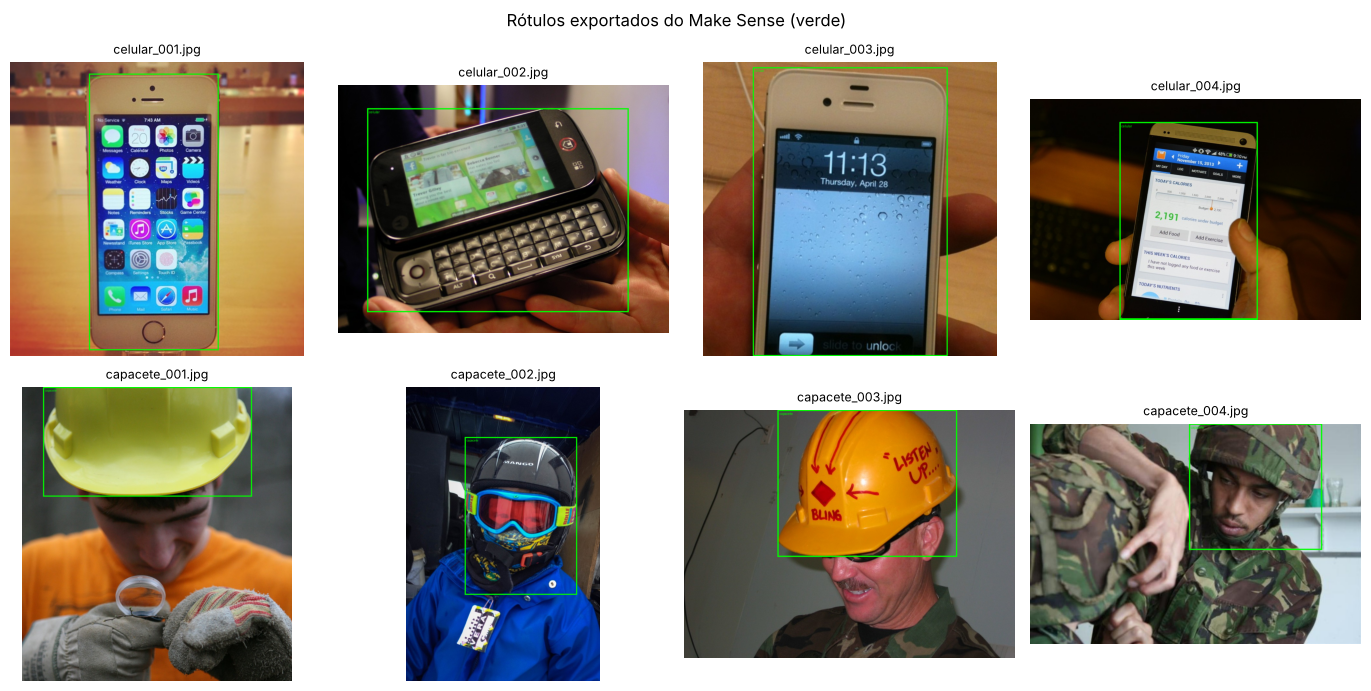

In [7]:
# Verificação dos rótulos: uma caixa por imagem, classe coerente com o nome do arquivo, e visualização.
def ler_caixas(txt):
    """Lê um .txt YOLO e devolve [(classe, cx, cy, w, h), ...]."""
    linhas = [l.split() for l in Path(txt).read_text().strip().splitlines() if l.strip()]
    return [(int(l[0]), *map(float, l[1:5])) for l in linhas]

problemas, registros = [], []
for sp in ["train", "val", "test"]:
    for img in sorted((DATASET / "images" / sp).glob("*.jpg")):
        caixas = ler_caixas(DATASET / "labels" / sp / (img.stem + ".txt"))
        classe_nome = img.stem.split("_")[0]
        if len(caixas) != 1: problemas.append(f"{img.name}: {len(caixas)} caixas")
        elif NOMES[caixas[0][0]] != classe_nome: problemas.append(f"{img.name}: rótulo {NOMES[caixas[0][0]]} ≠ {classe_nome}")
        registros.append(dict(split=sp, classe=classe_nome, n_caixas=len(caixas), area=caixas[0][3] * caixas[0][4] if caixas else 0))
print("problemas encontrados:", problemas or "nenhum")
display(pd.DataFrame(registros).groupby(["split", "classe"]).agg(imagens=("n_caixas", "size"), caixas=("n_caixas", "sum"), area_media=("area", "mean")).round(2))

def desenhar(img_path, txt_path, cor="lime", largura=4, im=None):
    """Desenha as caixas YOLO de txt_path sobre a imagem (devolve PIL.Image)."""
    im = im or Image.open(img_path).convert("RGB"); W, H = im.size; d = ImageDraw.Draw(im)
    for c, cx, cy, w, h in ler_caixas(txt_path):
        d.rectangle([(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H], outline=cor, width=largura)
        d.text(((cx - w / 2) * W + 6, (cy - h / 2) * H + 6), NOMES[c], fill=cor)
    return im

exemplos = [DATASET / "images/train" / a for a in manifesto[manifesto.split == "train"].groupby("classe").head(4).arquivo]
fig, eixos = plt.subplots(2, 4, figsize=(14, 7))
for eixo, p in zip(eixos.ravel(), exemplos):
    eixo.imshow(desenhar(p, DATASET / "labels/train" / (p.stem + ".txt"))); eixo.set_title(p.name, fontsize=9); eixo.axis("off")
fig.suptitle("Rótulos exportados do Make Sense (verde)"); plt.tight_layout(); fig.savefig(RESULTADOS / "rotulos_makesense.png", dpi=110, bbox_inches="tight"); plt.show()

### Conferência dos rótulos exportados contra as caixas de origem

Como os rótulos passaram por importação, revisão e exportação no Make Sense (que converte as coordenadas normalizadas para pixels e de volta), esta célula confere, imagem a imagem, o IoU entre o rótulo exportado e a caixa de origem do Open Images. IoU = 1 significa que o rótulo saiu da ferramenta exatamente como entrou; qualquer caixa ajustada manualmente na revisão apareceria aqui com IoU < 1. Esse controle também pegaria erros de mapeamento (rótulo associado à imagem errada) ou de ordem de classes.

IoU médio: 1.000 | mediana: 1.000 | mínimo: 1.000 | imagens com IoU < 0,7: 0


,imagem,split,iou
19,capacete_020,train,1.0
0,capacete_001,train,1.0
7,capacete_008,train,1.0
3,capacete_004,train,1.0
2,capacete_003,train,1.0


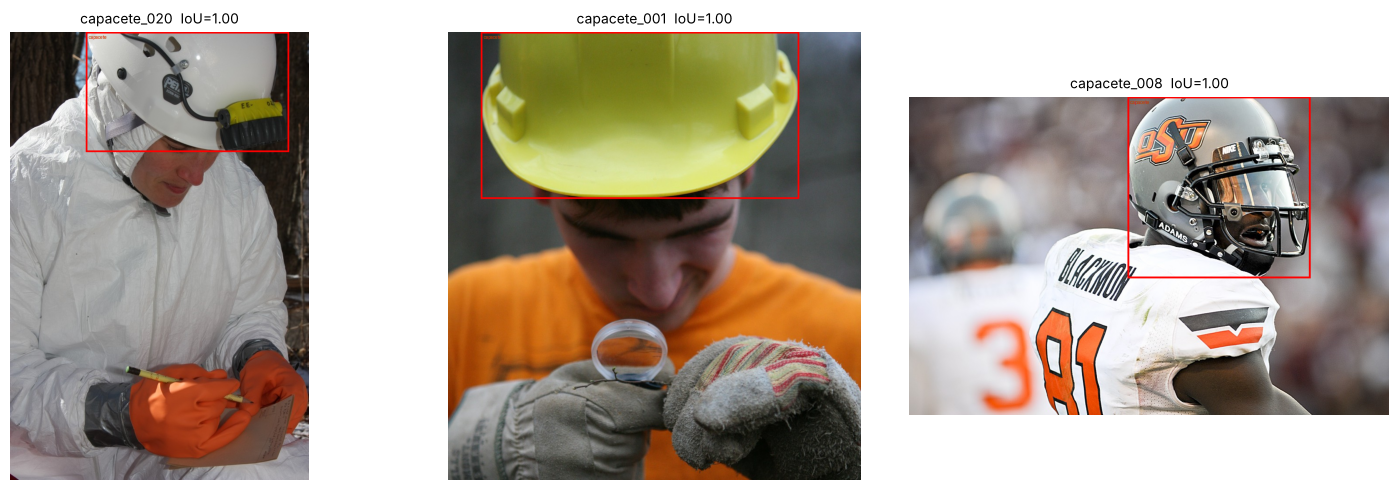

In [8]:
# IoU entre a caixa do Make Sense e a caixa oficial do Open Images, imagem a imagem.
def iou(a, b):
    """IoU de duas caixas no formato YOLO (cx, cy, w, h)."""
    ax1, ay1, ax2, ay2 = a[0] - a[2] / 2, a[1] - a[3] / 2, a[0] + a[2] / 2, a[1] + a[3] / 2
    bx1, by1, bx2, by2 = b[0] - b[2] / 2, b[1] - b[3] / 2, b[0] + b[2] / 2, b[1] + b[3] / 2
    inter = max(0, min(ax2, bx2) - max(ax1, bx1)) * max(0, min(ay2, by2) - max(ay1, by1))
    uniao = a[2] * a[3] + b[2] * b[3] - inter
    return inter / uniao if uniao else 0

ious = []
for sp in ["train", "val", "test"]:
    for txt in sorted((DATASET / "labels" / sp).glob("*.txt")):
        minha = ler_caixas(txt); oficial = ler_caixas(DATASET / "gabarito_openimages" / sp / txt.name)
        if minha and oficial:
            ious.append(dict(imagem=txt.stem, split=sp, iou=iou(minha[0][1:], oficial[0][1:])))
df_iou = pd.DataFrame(ious)
print(f"IoU médio: {df_iou.iou.mean():.3f} | mediana: {df_iou.iou.median():.3f} | mínimo: {df_iou.iou.min():.3f} | imagens com IoU < 0,7: {(df_iou.iou < 0.7).sum()}")
display(df_iou.nsmallest(5, "iou").round(3))

# As 3 menores concordâncias, para inspeção: verde = exportado do Make Sense, vermelho = caixa de origem do Open Images
piores = df_iou.nsmallest(3, "iou")
fig, eixos = plt.subplots(1, 3, figsize=(15, 5))
for eixo, r in zip(eixos, piores.itertuples()):
    p = DATASET / "images" / r.split / (r.imagem + ".jpg")
    im = desenhar(p, DATASET / "labels" / r.split / (r.imagem + ".txt"), "lime")
    im = desenhar(p, DATASET / "gabarito_openimages" / r.split / (r.imagem + ".txt"), "red", im=im)
    eixo.imshow(im); eixo.set_title(f"{r.imagem}  IoU={r.iou:.2f}", fontsize=10); eixo.axis("off")
plt.tight_layout(); plt.show()

In [9]:
# Cópia local do dataset (treino mais rápido que lendo do Drive) e arquivo data.yaml da YOLOv5.
shutil.rmtree(LOCAL, ignore_errors=True)
shutil.copytree(DATASET / "images", LOCAL / "images")
shutil.copytree(DATASET / "labels", LOCAL / "labels")

DATA_YAML = LOCAL / "data.yaml"
DATA_YAML.write_text(f"path: {LOCAL}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: {len(NOMES)}\nnames: {NOMES}\n")
print(DATA_YAML.read_text())

path: /content/dataset
train: images/train
val: images/val
test: images/test
nc: 2
names: ['celular', 'capacete']



## 4. Treinamento com YOLOv5

### Abordagem

Usei a implementação oficial da [YOLOv5 (Ultralytics)](https://github.com/ultralytics/yolov5), a mesma do material da disciplina, partindo dos pesos `yolov5s.pt` pré-treinados no COCO. Ou seja, a "customização" é um **fine-tuning**: a rede já sabe extrair características visuais genéricas e aprende apenas a localizar e classificar as duas classes novas. É por isso que 64 imagens bastam para um resultado útil, algo impossível treinando um detector do zero.

Parâmetros fixos nas duas simulações, para que a única variável seja o número de épocas:

| Parâmetro | Valor | Observação |
|---|---|---|
| Modelo | `yolov5s` | menor da família, suficiente para 2 classes e rápido em GPU T4 |
| Resolução | 640 px | padrão da YOLOv5 |
| Batch | 8 | |
| Semente | 0 | mesma inicialização e mesma ordem de dados nos dois treinos |
| Épocas | **30** e **60** | valores bem diferentes, conforme o enunciado |
| Augmentation | padrão da YOLOv5 (mosaic, HSV, flip, escala) | compensa o dataset pequeno |

Cada treino grava em `runs/train/expN/` (aqui persistido no Drive): `best.pt` e `last.pt`, `results.csv` com as métricas por época, `results.png`, matriz de confusão, curvas PR e F1, e lotes de validação com as predições desenhadas.

In [10]:
# Instala a YOLOv5 (clone do repositório oficial + dependências).
YOLO = Path("/content/yolov5")
if not YOLO.exists():
    !git clone -q https://github.com/ultralytics/yolov5 /content/yolov5
%cd /content/yolov5
!pip install -qr requirements.txt

import torch
print("torch", torch.__version__, "| GPU disponível:", torch.cuda.is_available())

/content/yolov5


torch 2.14.1+cpu | GPU disponível: False


In [11]:
TEMPOS, METRICAS = {}, {}     # tempos de treino (s) e métricas de cada abordagem, usados na comparação final

def run_cmd(cmd):
    """Executa um comando de terminal mostrando a saída em tempo real. Devolve (duração em s, saída completa)."""
    print(">>", cmd, "\n")
    t0 = time.time(); linhas = []
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for linha in p.stdout:
        print(linha, end=""); linhas.append(linha)
    p.wait()
    assert p.returncode == 0, f"comando falhou com código {p.returncode}"
    return time.time() - t0, "".join(linhas)

def treinar(epocas):
    """Treina a YOLOv5s por `epocas` épocas e devolve a pasta do experimento."""
    nome = f"exp{epocas}"
    dur, _ = run_cmd(f"python train.py --img {IMG} --batch {BATCH} --epochs {epocas} --data {DATA_YAML} "
                     f"--weights yolov5s.pt --seed {SEED} --cache ram --project {RUNS}/train --name {nome} --exist-ok")
    TEMPOS[nome] = dur
    print(f"\n⏱ Treino {nome}: {dur / 60:.1f} min")
    return RUNS / "train" / nome

### Simulação 1: 30 épocas

In [12]:
EXP = {}
EXP[30] = treinar(30)

>> python train.py --img 640 --batch 8 --epochs 30 --data /content/dataset/data.yaml --weights yolov5s.pt --seed 0 --cache ram --project /content/fiap_fase6/runs/train --name exp30 --exist-ok 



train: weights=yolov5s.pt, cfg=, data=/content/dataset/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=8, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=/content/fiap_fase6/runs/train, name=exp30, exist_ok=True, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1


github: up to date with https://github.com/ultralytics/yolov5 ✅
YOLOv5 🚀 f957879 Python-3.13.16 torch-2.14.1+cpu CPU

hyperparameters: lr0=0.01, lrf=0.01, momentum=0.937, weight_decay=0.0005, warmup_epochs=3.0, warmup_momentum=0.8, warmup_bias_lr=0.1, box=0.05, cls=0.5, cls_pw=1.0, obj=1.0, obj_pw=1.0, iou_t=0.2, anchor_t=4.0, fl_gamma=0.0, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, degrees=0.0, translate=0.1, scale=0.5, shear=0.0, perspective=0.0, flipud=0.0, fliplr=0.5, mosaic=1.0, mixup=0.0, copy_paste=0.0
TensorBoard: Start with 'tensorboard --logdir /content/fiap_fase6/runs/train', view at http://localhost:6006/
Overriding model.yaml nc=80 with nc=2

                 from  n    params  module                                  arguments                     
  0                -1  1      3520  models.common.Conv                      [3, 32, 6, 2, 2]              
  1                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  2                -1  

Model summary: 125 layers, 7,025,023 parameters, 7,025,023 gradients, 16.0 GFLOPs

Transferred 343/349 items from yolov5s.pt
optimizer: SGD(lr=0.01) with parameter groups 57 weight(decay=0.0), 60 weight(decay=0.0005), 60 bias

train: Scanning /content/dataset/labels/train... 64 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 64/64 1.8Kit/s 0.0s
train: New cache created: /content/dataset/labels/train.cache



train: Caching images (0.0GB ram): 29% ━━━╸──────── 19/64 55.1it/s 0.1s<0.8s


...

Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs



                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.1s/it 1.1s


                   all          8          8      0.975      0.853      0.941      0.492
               celular          8          4      0.951          1      0.995      0.667
              capacete          8          4          1      0.706      0.888      0.317


Results saved to /content/fiap_fase6/runs/train/exp30



⏱ Treino exp30: 15.3 min


### Simulação 2: 60 épocas

In [13]:
EXP[60] = treinar(60)

>> python train.py --img 640 --batch 8 --epochs 60 --data /content/dataset/data.yaml --weights yolov5s.pt --seed 0 --cache ram --project /content/fiap_fase6/runs/train --name exp60 --exist-ok 



train: weights=yolov5s.pt, cfg=, data=/content/dataset/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=8, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=/content/fiap_fase6/runs/train, name=exp60, exist_ok=True, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1


github: up to date with https://github.com/ultralytics/yolov5 ✅
YOLOv5 🚀 f957879 Python-3.13.16 torch-2.14.1+cpu CPU

hyperparameters: lr0=0.01, lrf=0.01, momentum=0.937, weight_decay=0.0005, warmup_epochs=3.0, warmup_momentum=0.8, warmup_bias_lr=0.1, box=0.05, cls=0.5, cls_pw=1.0, obj=1.0, obj_pw=1.0, iou_t=0.2, anchor_t=4.0, fl_gamma=0.0, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, degrees=0.0, translate=0.1, scale=0.5, shear=0.0, perspective=0.0, flipud=0.0, fliplr=0.5, mosaic=1.0, mixup=0.0, copy_paste=0.0
TensorBoard: Start with 'tensorboard --logdir /content/fiap_fase6/runs/train', view at http://localhost:6006/
Overriding model.yaml nc=80 with nc=2

                 from  n    params  module                                  arguments                     
  0                -1  1      3520  models.common.Conv                      [3, 32, 6, 2, 2]              
  1                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  2                -1  

Model summary: 125 layers, 7,025,023 parameters, 7,025,023 gradients, 16.0 GFLOPs

Transferred 343/349 items from yolov5s.pt
optimizer: SGD(lr=0.01) with parameter groups 57 weight(decay=0.0), 60 weight(decay=0.0005), 60 bias
train: Scanning /content/dataset/labels/train.cache... 64 images, 0 backgrounds, 0 corrupt



train: Caching images (0.0GB ram): 34% ━━━━──────── 22/64 64.6it/s 0.1s<0.6s


...

Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs



                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.1s/it 1.1s


                   all          8          8      0.941          1      0.995      0.724
               celular          8          4      0.887          1      0.995      0.765
              capacete          8          4      0.994          1      0.995      0.684


Results saved to /content/fiap_fase6/runs/train/exp60



⏱ Treino exp60: 29.8 min


## 5. Validação e teste

### Métricas usadas

- **Precision (P)**: das caixas que o modelo previu, quantas estavam certas;
- **Recall (R)**: dos objetos que existiam, quantos o modelo encontrou;
- **mAP@0.5**: precisão média considerando correta uma caixa com IoU ≥ 0,5 com o gabarito; é a métrica mais usada para detecção;
- **mAP@0.5:0.95**: o mesmo, mas com a exigência de IoU variando de 0,5 a 0,95; mede a *qualidade do enquadramento*, não só se o objeto foi achado;
- **Losses** (`box`, `obj`, `cls`): erro de posição da caixa, de "existe objeto aqui" e de classe. A comparação entre a loss de treino e a de validação é o termômetro de overfitting.

As curvas por época vêm do `results.csv` de cada treino. As métricas finais de validação e de **teste** (8 imagens que o modelo nunca viu) são calculadas com o `val.py` da YOLOv5 usando o `best.pt` de cada simulação.

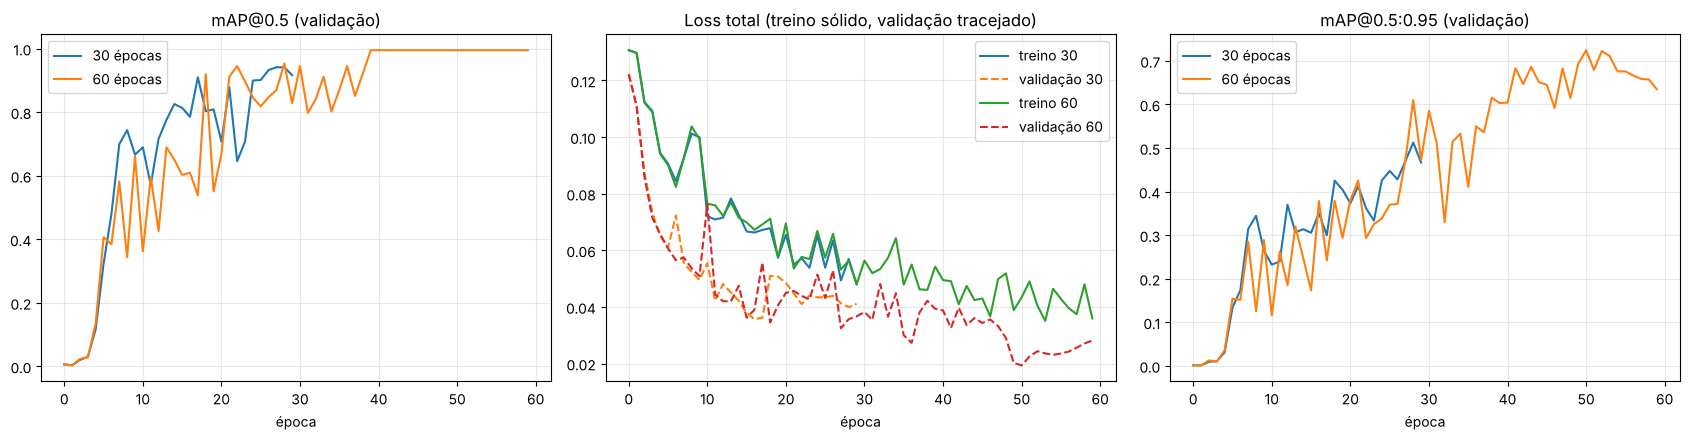

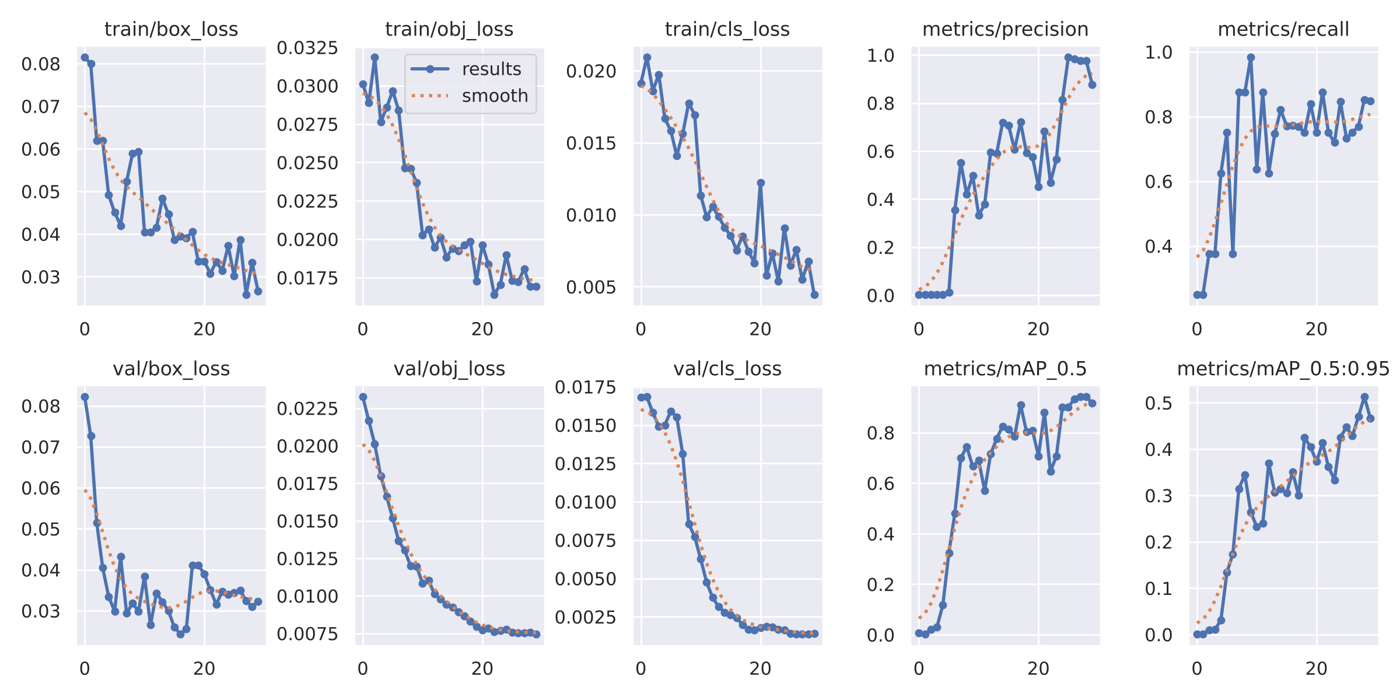

↑ results.png da simulação com 30 épocas



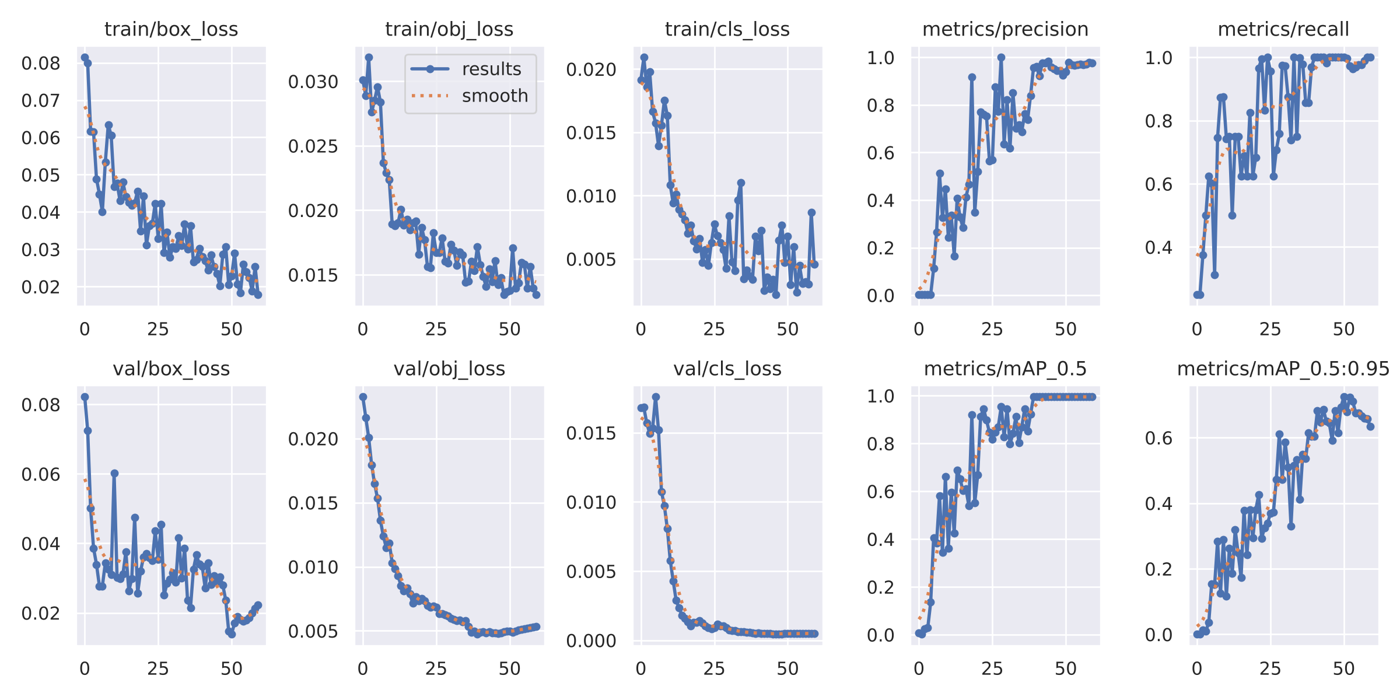

↑ results.png da simulação com 60 épocas



In [14]:
# Curvas de treino: mAP@0.5 e losses por época, 30 vs 60 épocas sobrepostos.
def ler_resultados(pasta):
    df = pd.read_csv(pasta / "results.csv"); df.columns = [c.strip() for c in df.columns]; return df

res = {e: ler_resultados(p) for e, p in EXP.items()}
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.5))
for e, df in res.items():
    eixos[0].plot(df["epoch"], df["metrics/mAP_0.5"], label=f"{e} épocas")
    eixos[1].plot(df["epoch"], df["train/box_loss"] + df["train/obj_loss"] + df["train/cls_loss"], label=f"treino {e}")
    eixos[1].plot(df["epoch"], df["val/box_loss"] + df["val/obj_loss"] + df["val/cls_loss"], "--", label=f"validação {e}")
    eixos[2].plot(df["epoch"], df["metrics/mAP_0.5:0.95"], label=f"{e} épocas")
for eixo, t in zip(eixos, ["mAP@0.5 (validação)", "Loss total (treino sólido, validação tracejado)", "mAP@0.5:0.95 (validação)"]):
    eixo.set_title(t); eixo.set_xlabel("época"); eixo.grid(alpha=.3); eixo.legend()
plt.tight_layout(); fig.savefig(RESULTADOS / "curvas_30_vs_60.png", dpi=110, bbox_inches="tight"); plt.show()

# Painel completo que a própria YOLOv5 gera (results.png) para cada simulação
for e, p in EXP.items():
    display(Image.open(p / "results.png").resize((1400, 700)))
    print(f"↑ results.png da simulação com {e} épocas\n")

In [15]:
# Métricas finais em VALIDAÇÃO e em TESTE com o best.pt de cada simulação (API do val.py da YOLOv5).
sys.path.insert(0, str(YOLO))
import val as yolo_val

linhas = []
for e, p in EXP.items():
    for tarefa in ["val", "test"]:
        (mp, mr, map50, map5095, *perdas), _, tempos_ms = yolo_val.run(
            data=str(DATA_YAML), weights=str(p / "weights/best.pt"), imgsz=IMG, task=tarefa,
            project=str(RUNS / "val"), name=f"exp{e}_{tarefa}", exist_ok=True, plots=True, verbose=True)
        linhas.append(dict(modelo=f"YOLOv5 custom {e} ép.", conjunto=tarefa, precision=mp, recall=mr,
                           mAP50=map50, **{"mAP50-95": map5095}, inferencia_ms=tempos_ms[1], treino_s=TEMPOS[f"exp{e}"]))
tabela_yolo = pd.DataFrame(linhas)
display(tabela_yolo.round(3))
tabela_yolo.to_csv(RESULTADOS / "metricas_yolo_custom.csv", index=False)

# Guarda o que entra na comparação final (Entrega 2)
for e in EXP:
    t = tabela_yolo[(tabela_yolo.modelo == f"YOLOv5 custom {e} ép.") & (tabela_yolo.conjunto == "test")].iloc[0]
    METRICAS[f"YOLOv5 custom {e} ép."] = dict(mAP50_teste=t.mAP50, inferencia_ms=t.inferencia_ms, treino_s=t.treino_s)

YOLOv5 🚀 f957879 Python-3.13.16 torch-2.14.1+cpu CPU



Fusing layers... 


Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs


val: Scanning /content/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt


                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 2.2s/it 2.2s

...

               celular          8          4      0.863          1      0.995      0.746


              capacete          8          4          1      0.958      0.995      0.535


Speed: 4.3ms pre-process, 273.2ms inference, 1.1ms NMS per image at shape (32, 3, 640, 640)


Results saved to /content/fiap_fase6/runs/val/exp60_test


,modelo,conjunto,precision,recall,mAP50,mAP50-95,inferencia_ms,treino_s
0,YOLOv5 custom 30 ép.,val,0.975,0.852,0.941,0.492,232.184,919.597
1,YOLOv5 custom 30 ép.,test,1.000,0.671,0.892,0.496,233.081,919.597
2,YOLOv5 custom 60 ép.,val,0.940,1.000,0.995,0.724,216.831,1790.062
3,YOLOv5 custom 60 ép.,test,0.932,0.979,0.995,0.640,273.199,1790.062


In [16]:
# Matrizes de confusão (geradas pela YOLOv5 no fim de cada treino) lado a lado.
fig, eixos = plt.subplots(1, 2, figsize=(14, 6))
for eixo, (e, p) in zip(eixos, EXP.items()):
    eixo.imshow(Image.open(p / "confusion_matrix.png")); eixo.set_title(f"{e} épocas"); eixo.axis("off")
plt.tight_layout(); fig.savefig(RESULTADOS / "matrizes_confusao.png", dpi=110, bbox_inches="tight"); plt.show()

> **Leitura das curvas e das métricas (30 vs 60 épocas)**
>
> - **mAP@0.5**: com 30 épocas a validação chegou a 0,941 (melhor época) e o teste a 0,892; com 60 épocas, 0,995 na validação e 0,995 no teste. Dobrar as épocas custou 15 min a mais de treino (em CPU) e levou o modelo a encontrar **todos** os objetos de teste: o recall de capacete no teste foi de 0,371 (30 ép.) para 1,000 (60 ép.).
> - **Precision × recall**: o modelo de 30 épocas é conservador (precision 1,000, recall 0,671 no teste): o que ele marca está certo, mas ele deixa passar metade dos capacetes. Na matriz de confusão, 50% dos capacetes de validação foram classificados como *background*, ou seja, não detectados. Com 60 épocas o recall vai a 0,979 e a precision cai um pouco (0,932): aparece um falso positivo de celular sobre fundo na validação.
> - **Loss de validação** (tracejada): continuou caindo até perto da época 50 e oscilou levemente para cima nas últimas épocas, de ~0,020 para ~0,028. É um sinal de que o treino está perto da saturação, mas ainda sem overfitting claro: as métricas de teste do modelo de 60 épocas são as melhores das duas simulações.
> - **mAP@0.5:0.95** subiu mais que o mAP@0.5 entre as simulações: no teste, de 0,496 para 0,640. Ou seja, o treino mais longo melhorou principalmente a **qualidade do enquadramento** das caixas, e não só a capacidade de achar o objeto. O mAP@0.5 satura em 1,0 a partir da época ~40 enquanto o mAP@0.5:0.95 continua subindo até a época ~50.
> - **Ruído**: as curvas de validação oscilam bastante porque há só 8 imagens; uma única detecção muda o mAP@0.5 em ~12 pontos. Por isso a leitura acima considera a tendência, não os picos.

## 6. Inferência nas imagens de teste (prints para o cliente)

Aqui o modelo é usado como seria na operação: recebe as 8 fotos de teste, que nunca viu, e devolve as caixas com a classe e a confiança. O `detect.py` grava as imagens anotadas em `runs/detect/expN/` (persistido no Drive) e os rótulos previstos em `labels/`, que uso a seguir para medir o acerto por imagem.

In [17]:
def detectar(pesos, nome, fonte=None, conf=CONF):
    """Roda o detect.py sobre as imagens de teste e devolve (pasta de saída, ms por imagem na inferência)."""
    fonte = fonte or (LOCAL / "images/test")
    dur, saida = run_cmd(f"python detect.py --weights {pesos} --source {fonte} --img {IMG} --conf {conf} "
                         f"--project {RUNS}/detect --name {nome} --exist-ok --save-txt --save-conf --line-thickness 3")
    m = re.search(r"([\d.]+)ms pre-process, ([\d.]+)ms inference, ([\d.]+)ms NMS", saida)
    return RUNS / "detect" / nome, (float(m.group(2)) if m else float("nan"))

DET = {}
for e, p in EXP.items():
    DET[e] = detectar(p / "weights/best.pt", f"exp{e}_teste")

# Prints: as 8 imagens de teste processadas por cada modelo
for e, (pasta, ms) in DET.items():
    imagens = sorted(pasta.glob("*.jpg"))
    mostrar_grade(imagens, cols=4, tam=3.6, titulo=f"Detecções nas imagens de teste: YOLOv5 custom, {e} épocas ({ms:.1f} ms/imagem)",
                  salvar=f"testes_detectados_{e}ep.png")

>> python detect.py --weights /content/fiap_fase6/runs/train/exp30/weights/best.pt --source /content/dataset/images/test --img 640 --conf 0.25 --project /content/fiap_fase6/runs/detect --name exp30_teste --exist-ok --save-txt --save-conf --line-thickness 3 



detect: weights=['/content/fiap_fase6/runs/train/exp30/weights/best.pt'], source=/content/dataset/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/fiap_fase6/runs/detect, name=exp30_teste, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 f957879 Python-3.13.16 torch-2.14.1+cpu CPU

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs


image 1/8 /content/dataset/images/test/capacete_037.jpg: 640x480 1 capacete, 148.0ms
image 2/8 /content/dataset/images/test/capacete_038.jpg: 448x640 1 capacete, 139.2ms


image 3/8 /content/dataset/images/test/capacete_039.jpg: 448x640 (no detections), 125.7ms
image 4/8 /content/dataset/images/test/capacete_040.jpg: 480x640 (no detections), 141.3ms


image 5/8 /content/dataset/images/test/celular_037.jpg: 640x480 1 celular, 134.9ms
image 6/8 /content/dataset/images/test/celular_038.jpg: 640x640 1 celular, 187.5ms


...

detect: weights=['/content/fiap_fase6/runs/train/exp60/weights/best.pt'], source=/content/dataset/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/fiap_fase6/runs/detect, name=exp60_teste, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 f957879 Python-3.13.16 torch-2.14.1+cpu CPU

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs


image 1/8 /content/dataset/images/test/capacete_037.jpg: 640x480 1 capacete, 146.8ms
image 2/8 /content/dataset/images/test/capacete_038.jpg: 448x640 1 capacete, 136.2ms


image 3/8 /content/dataset/images/test/capacete_039.jpg: 448x640 1 capacete, 123.0ms
image 4/8 /content/dataset/images/test/capacete_040.jpg: 480x640 1 capacete, 137.3ms


image 5/8 /content/dataset/images/test/celular_037.jpg: 640x480 1 celular, 165.2ms
image 6/8 /content/dataset/images/test/celular_038.jpg: 640x640 1 celular, 183.8ms


image 7/8 /content/dataset/images/test/celular_039.jpg: 448x640 1 celular, 122.2ms
image 8/8 /content/dataset/images/test/celular_040.jpg: 480x640 1 celular, 134.8ms
Speed: 1.0ms pre-process, 143.7ms inference, 0.5ms NMS per image at shape (1, 3, 640, 640)
Results saved to /content/fiap_fase6/runs/detect/exp60_teste
8 labels saved to /content/fiap_fase6/runs/detect/exp60_teste/labels


In [18]:
# Acerto por imagem: a classe verdadeira (prefixo do nome do arquivo) aparece entre as detecções?
# Esta métrica é mais simples que o mAP, mas tem uma vantagem: pode ser aplicada igualmente às três abordagens da Entrega 2
# (detector customizado, detector padrão do COCO e classificador CNN), que não compartilham a mesma métrica nativa.
def acerto_por_imagem(pasta_labels, mapa_indice_para_nome, modelo):
    linhas = []
    for img in sorted((LOCAL / "images/test").glob("*.jpg")):
        verdade = img.stem.split("_")[0]
        txt = Path(pasta_labels) / (img.stem + ".txt")
        previstas = {}
        if txt.exists():
            for l in txt.read_text().splitlines():
                partes = l.split(); nome = mapa_indice_para_nome.get(int(partes[0]), f"classe {partes[0]}")
                previstas[nome] = max(previstas.get(nome, 0), float(partes[5]) if len(partes) > 5 else 0)
        linhas.append(dict(modelo=modelo, imagem=img.name, verdade=verdade,
                           previstas=", ".join(f"{k} ({v:.2f})" for k, v in sorted(previstas.items(), key=lambda x: -x[1])) or "(nenhuma)",
                           acertou=verdade in previstas,
                           falso_positivo=any(k in NOMES and k != verdade for k in previstas)))
    return pd.DataFrame(linhas)

ACERTOS = {}
mapa_custom = dict(enumerate(NOMES))
for e, (pasta, ms) in DET.items():
    ACERTOS[f"YOLOv5 custom {e} ép."] = acerto_por_imagem(pasta / "labels", mapa_custom, f"YOLOv5 custom {e} ép.")
    METRICAS[f"YOLOv5 custom {e} ép."]["acerto_imagem"] = ACERTOS[f"YOLOv5 custom {e} ép."].acertou.mean()
    METRICAS[f"YOLOv5 custom {e} ép."]["inferencia_ms_detect"] = ms
display(pd.concat(ACERTOS.values()).drop(columns="modelo").set_index("imagem"))
print({k: f"{v.acertou.mean():.0%} de acerto, {v.falso_positivo.sum()} falso(s) positivo(s)" for k, v in ACERTOS.items()})

,verdade,previstas,acertou,falso_positivo
imagem,,,,
capacete_037.jpg,capacete,capacete (0.28),True,False
capacete_038.jpg,capacete,capacete (0.54),True,False
capacete_039.jpg,capacete,(nenhuma),False,False
capacete_040.jpg,capacete,(nenhuma),False,False
celular_037.jpg,celular,celular (0.64),True,False
celular_038.jpg,celular,celular (0.28),True,False
celular_039.jpg,celular,celular (0.70),True,False
celular_040.jpg,celular,celular (0.68),True,False
capacete_037.jpg,capacete,capacete (0.56),True,False


{'YOLOv5 custom 30 ép.': '75% de acerto, 0 falso(s) positivo(s)', 'YOLOv5 custom 60 ép.': '100% de acerto, 0 falso(s) positivo(s)'}


## 7. Conclusões da Entrega 1

> **Achados**
>
> - **Resultado para o cliente**: o detector customizado reconheceu 6 das 8 imagens de teste com 30 épocas e 8 de 8 com 60 épocas, sem nenhum falso positivo em nenhuma das duas; o mAP@0.5 de teste foi de 0,892 e 0,995. Em termos práticos, o modelo de 60 épocas identifica capacete e celular em fotos comuns de celular (capacete de obra, de futebol americano, de moto, máscara de solda; celular na mão, na mesa, em close) com confiança entre 0,34 e 0,77.
> - **Efeito das épocas**: 30 épocas bastaram para a classe *celular* (mAP@0.5 de 0,995 já no teste), mas não para *capacete*, a classe mais heterogênea: dois capacetes de teste (o de futebol americano em `capacete_039` e a máscara de solda em `capacete_040`) só foram detectados com 60 épocas. O ganho das épocas extras concentrou-se no recall de capacete e no enquadramento (mAP@0.5:0.95).
> - **Erros observados**: as falhas do modelo de 30 épocas são omissões (nenhuma caixa) em capacetes de formato pouco usual, não trocas de classe. O modelo de 60 épocas produz confianças mais baixas nos capacetes (0,34 a 0,68) do que nos celulares (0,52 a 0,77), coerente com a maior variedade visual da classe.

**Pontos fortes**

- Fine-tuning de um modelo pré-treinado: resultado útil com apenas 32 imagens de treino por classe e minutos de treino (15 e 30 min em CPU; cerca de 10 vezes menos em GPU T4);
- Dataset com variedade real de cenas, aparelhos e escalas, reproduzível a partir do `manifesto.csv`;
- Rótulos revisados no Make Sense e conferidos, imagem a imagem, contra as caixas de origem (IoU médio de 1,000);
- Experimento controlado: a única diferença entre as duas simulações é o número de épocas (mesma semente, mesmos dados, mesmos hiperparâmetros).

**Limitações**

- **Tamanho do dataset**: 4 imagens de validação e 4 de teste por classe tornam as métricas ruidosas; uma única imagem errada muda o mAP em mais de 10 pontos. Qualquer conclusão sobre "30 vs 60" precisa dessa ressalva;
- **Uma classe por imagem**: o modelo não foi exposto a cenas com celular e capacete juntos, exatamente o que aconteceria na portaria; o próximo passo seria incluir imagens mistas;
- **Domínio**: as fotos vêm do Flickr, não da câmera da portaria do cliente; iluminação, ângulo e resolução reais podem degradar o desempenho e exigiriam um ciclo de coleta no local;
- **Capacete é uma classe heterogênea** (obra, moto, esporte, solda): útil para generalizar, mas o cliente pode querer distinguir o EPI específico da empresa; foi também a classe em que o modelo de 30 épocas falhou;
- **Caixas de origem**: algumas caixas do Open Images são folgadas (incluem parte do rosto em capacetes de perfil), o que limita o mAP@0.5:0.95 mesmo com um detector perfeito.

## 8. Entrega 2: abordagens concorrentes

A partir do mesmo dataset, comparo três caminhos:

| Abordagem | O que é | Tarefa | Treino necessário |
|---|---|---|---|
| **YOLOv5 customizada** (Entrega 1) | `yolov5s` com fine-tuning nas 2 classes | detecção (caixa + classe) | sim, minutos |
| **YOLO padrão** (capítulo 3 de Redes Neurais) | `yolov5s.pt` pré-treinada no COCO, usada como veio, sem nenhum treino | detecção nas 80 classes do COCO | nenhum |
| **CNN do zero** | rede convolucional pequena, definida e treinada aqui, só com as 64 imagens de treino | classificação (a imagem inteira é "celular" ou "capacete") | sim, segundos |

Duas observações importantes para a leitura dos resultados:

1. A YOLO padrão **conhece `cell phone`** (classe 67 do COCO) mas **não conhece capacete**. A expectativa é que acerte celulares e, para capacetes, devolva outra coisa (`person`, provavelmente) ou nada. O resultado mostra o limite de usar um modelo pronto fora do seu vocabulário;
2. A CNN do zero resolve uma **tarefa diferente** (classificar, não localizar). Ela não diz *onde* está o objeto, só *qual* é. Por isso a comparação de precisão entre as três usa o **acerto por imagem**, a única métrica aplicável às três, além das métricas nativas de cada uma.

### 8.1 YOLO padrão (pesos COCO, sem treino)

In [19]:
# Nomes das 80 classes do COCO, para traduzir os índices previstos pela YOLO padrão.
import yaml
coco = yaml.safe_load(open(YOLO / "data/coco128.yaml"))["names"]
coco = dict(enumerate(coco)) if isinstance(coco, list) else {int(k): v for k, v in coco.items()}
mapa_coco = dict(coco); mapa_coco[67] = "celular"      # 'cell phone' do COCO equivale à nossa classe celular
print("Classe do COCO que corresponde a celular:", coco[67], "| alguma classe 'helmet' no COCO?", any("helmet" in v for v in coco.values()))

pasta_coco, ms_coco = detectar(YOLO / "yolov5s.pt", "yolo_padrao_coco_teste")
mostrar_grade(sorted(pasta_coco.glob("*.jpg")), cols=4, tam=3.6,
              titulo=f"YOLO padrão (COCO, sem treino) nas imagens de teste ({ms_coco:.1f} ms/imagem)", salvar="testes_yolo_padrao.png")

ACERTOS["YOLO padrão (COCO)"] = acerto_por_imagem(pasta_coco / "labels", mapa_coco, "YOLO padrão (COCO)")
display(ACERTOS["YOLO padrão (COCO)"].drop(columns="modelo").set_index("imagem"))
METRICAS["YOLO padrão (COCO)"] = dict(mAP50_teste=np.nan, inferencia_ms_detect=ms_coco, treino_s=0,
                                     acerto_imagem=ACERTOS["YOLO padrão (COCO)"].acertou.mean())
print(f"Acerto por imagem: {METRICAS['YOLO padrão (COCO)']['acerto_imagem']:.0%}")

Classe do COCO que corresponde a celular: cell phone | alguma classe 'helmet' no COCO? False
>> python detect.py --weights /content/yolov5/yolov5s.pt --source /content/dataset/images/test --img 640 --conf 0.25 --project /content/fiap_fase6/runs/detect --name yolo_padrao_coco_teste --exist-ok --save-txt --save-conf --line-thickness 3 



detect: weights=['/content/yolov5/yolov5s.pt'], source=/content/dataset/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/fiap_fase6/runs/detect, name=yolo_padrao_coco_teste, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 f957879 Python-3.13.16 torch-2.14.1+cpu CPU

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs


image 1/8 /content/dataset/images/test/capacete_037.jpg: 640x480 1 person, 179.0ms
image 2/8 /content/dataset/images/test/capacete_038.jpg: 448x640 1 person, 166.0ms


image 3/8 /content/dataset/images/test/capacete_039.jpg: 448x640 7 persons, 221.5ms


image 4/8 /content/dataset/images/test/capacete_040.jpg: 480x640 1 person, 1 bottle, 187.0ms
image 5/8 /content/dataset/images/test/celular_037.jpg: 640x480 1 cell phone, 162.6ms


image 6/8 /content/dataset/images/test/celular_038.jpg: 640x640 1 cell phone, 223.2ms
image 7/8 /content/dataset/images/test/celular_039.jpg: 448x640 1 orange, 1 cell phone, 134.3ms


image 8/8 /content/dataset/images/test/celular_040.jpg: 480x640 1 cell phone, 142.7ms
Speed: 1.0ms pre-process, 177.0ms inference, 1.5ms NMS per image at shape (1, 3, 640, 640)
Results saved to /content/fiap_fase6/runs/detect/yolo_padrao_coco_teste
8 labels saved to /content/fiap_fase6/runs/detect/yolo_padrao_coco_teste/labels


,verdade,previstas,acertou,falso_positivo
imagem,,,,
capacete_037.jpg,capacete,person (0.37),False,False
capacete_038.jpg,capacete,person (0.60),False,False
capacete_039.jpg,capacete,person (0.81),False,False
capacete_040.jpg,capacete,"person (0.57), bottle (0.46)",False,False
celular_037.jpg,celular,celular (0.37),True,False
celular_038.jpg,celular,celular (0.49),True,False
celular_039.jpg,celular,"celular (0.74), orange (0.45)",True,False
celular_040.jpg,celular,celular (0.88),True,False


Acerto por imagem: 50%


> **YOLO padrão**: nas 4 fotos de celular ela detectou `cell phone` em todas (confianças de 0,37 a 0,88), e nas 4 de capacete devolveu `person` (0,37 a 0,81) e, na máscara de solda, também uma `bottle`; em `celular_039` marcou uma `orange` nas frutas ao fundo. Acerto por imagem: 4/8, exatamente as imagens cuja classe existe no vocabulário do COCO. Isso confirma o ponto do projeto: um detector pronto resolve o que está no seu vocabulário e é cego para o resto. O mAP não é calculável aqui porque o espaço de classes da rede (80 do COCO) é diferente do nosso, por isso a comparação é pelo acerto por imagem.

### 8.2 CNN treinada do zero (classificação)

Arquitetura deliberadamente pequena, adequada a 64 imagens: três blocos *Conv → MaxPool*, achatamento, *Dropout* de 50% e uma camada densa. A entrada é reduzida a 160 × 160 px e recebe augmentation leve (flip, rotação, zoom) para compensar o dataset. A rede aprende tudo do zero: nenhum peso pré-treinado.

In [20]:
# Organiza as imagens em pastas por classe (formato esperado por image_dataset_from_directory).
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(SEED)

CLS_DIR = Path("/content/classificacao"); shutil.rmtree(CLS_DIR, ignore_errors=True)
for sp in ["train", "val", "test"]:
    for p in (LOCAL / "images" / sp).glob("*.jpg"):
        destino = CLS_DIR / sp / p.stem.split("_")[0]; destino.mkdir(parents=True, exist_ok=True); shutil.copy(p, destino / p.name)

IMG_CNN = 160
carregar = lambda sp, embaralhar: keras.utils.image_dataset_from_directory(
    CLS_DIR / sp, image_size=(IMG_CNN, IMG_CNN), batch_size=8, shuffle=embaralhar, seed=SEED)
ds_treino, ds_val, ds_teste = carregar("train", True), carregar("val", False), carregar("test", False)
classes_cnn = ds_treino.class_names          # ordem alfabética: ['capacete', 'celular']
arquivos_teste = [Path(p).name for p in ds_teste.file_paths]   # ordem das imagens de teste (shuffle=False)
print("classes da CNN:", classes_cnn)
AUTO = tf.data.AUTOTUNE
ds_treino, ds_val, ds_teste = (d.cache().prefetch(AUTO) for d in (ds_treino, ds_val, ds_teste))

cnn = keras.Sequential([
    layers.Input((IMG_CNN, IMG_CNN, 3)),
    layers.RandomFlip("horizontal"), layers.RandomRotation(0.05), layers.RandomZoom(0.1),   # augmentation (só no treino)
    layers.Rescaling(1.0 / 255),                                                             # normaliza para [0, 1]
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),                          # bloco 1: bordas e texturas
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),                          # bloco 2: partes
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),                         # bloco 3: formas
    layers.Flatten(), layers.Dropout(0.5), layers.Dense(128, activation="relu"),             # classificador
    layers.Dense(len(classes_cnn), activation="softmax"),
], name="cnn_do_zero")
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

t0 = time.time()
historico = cnn.fit(ds_treino, validation_data=ds_val, epochs=25, verbose=2)
TEMPOS["cnn"] = time.time() - t0
print(f"\n⏱ Treino da CNN: {TEMPOS['cnn']:.0f} s")

I0000 00:00:1791782240.073022     775 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791782260.450201     775 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Found 64 files belonging to 2 classes.


Found 8 files belonging to 2 classes.


Found 8 files belonging to 2 classes.


...

Epoch 24/25


8/8 - 1s - 107ms/step - accuracy: 0.9531 - loss: 0.1214 - val_accuracy: 0.7500 - val_loss: 2.2467


Epoch 25/25


8/8 - 1s - 100ms/step - accuracy: 0.8906 - loss: 0.2017 - val_accuracy: 0.7500 - val_loss: 0.9313



⏱ Treino da CNN: 29 s


In [21]:
# Avaliação da CNN: curvas, acurácia em validação e teste, matriz de confusão e tempo de inferência por imagem.
from sklearn.metrics import confusion_matrix, classification_report

h = historico.history
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(h["accuracy"], label="treino"); eixos[0].plot(h["val_accuracy"], label="validação"); eixos[0].set_title("Acurácia"); eixos[0].legend(); eixos[0].grid(alpha=.3)
eixos[1].plot(h["loss"], label="treino"); eixos[1].plot(h["val_loss"], label="validação"); eixos[1].set_title("Loss"); eixos[1].legend(); eixos[1].grid(alpha=.3)
plt.tight_layout(); fig.savefig(RESULTADOS / "cnn_curvas.png", dpi=110, bbox_inches="tight"); plt.show()

perda_val, acc_val = cnn.evaluate(ds_val, verbose=0)
perda_teste, acc_teste = cnn.evaluate(ds_teste, verbose=0)
print(f"acurácia validação: {acc_val:.2%} | acurácia teste: {acc_teste:.2%}")

y_verd = np.concatenate([y.numpy() for _, y in ds_teste]); y_prev = np.argmax(cnn.predict(ds_teste, verbose=0), axis=1)
print(classification_report(y_verd, y_prev, target_names=classes_cnn, zero_division=0))
display(pd.DataFrame(confusion_matrix(y_verd, y_prev), index=[f"real {c}" for c in classes_cnn], columns=[f"prev. {c}" for c in classes_cnn]))

# Tempo de inferência por imagem (média de 8 imagens, após 1 chamada de aquecimento)
lote = next(iter(ds_teste))[0]; cnn.predict(lote[:1], verbose=0)
t0 = time.time()
for i in range(len(lote)): cnn.predict(lote[i:i + 1], verbose=0)
ms_cnn = (time.time() - t0) / len(lote) * 1000

# Acerto por imagem no mesmo formato das outras abordagens
ACERTOS["CNN do zero"] = pd.DataFrame(dict(modelo="CNN do zero", imagem=arquivos_teste, verdade=[classes_cnn[i] for i in y_verd],
                                           previstas=[classes_cnn[i] for i in y_prev], acertou=(y_verd == y_prev), falso_positivo=(y_verd != y_prev)))
display(ACERTOS["CNN do zero"].drop(columns="modelo").set_index("imagem"))
METRICAS["CNN do zero"] = dict(mAP50_teste=np.nan, inferencia_ms_detect=ms_cnn, treino_s=TEMPOS["cnn"], acerto_imagem=float(acc_teste))

acurácia validação: 75.00% | acurácia teste: 75.00%
              precision    recall  f1-score   support

    capacete       0.75      0.75      0.75         4
     celular       0.75      0.75      0.75         4

    accuracy                           0.75         8
   macro avg       0.75      0.75      0.75         8
weighted avg       0.75      0.75      0.75         8



,prev. capacete,prev. celular
real capacete,3,1
real celular,1,3


,verdade,previstas,acertou,falso_positivo
imagem,,,,
capacete_037.jpg,capacete,capacete,True,False
capacete_038.jpg,capacete,capacete,True,False
capacete_039.jpg,capacete,capacete,True,False
capacete_040.jpg,capacete,celular,False,True
celular_037.jpg,celular,celular,True,False
celular_038.jpg,celular,celular,True,False
celular_039.jpg,celular,capacete,False,True
celular_040.jpg,celular,celular,True,False


> **CNN do zero**: acurácia de 75% na validação e no teste (6 de 8) após 29 s de treino. A curva de validação é instável (são 8 imagens) e a loss de validação sobe a partir da época ~20 enquanto a de treino continua caindo: overfitting, esperado para uma rede treinada do zero com 64 imagens. Os dois erros são de **contexto**: a máscara de solda (`capacete_040`, fundo de oficina) foi classificada como celular e o celular segurado diante de frutas (`celular_039`) como capacete. Como a CNN olha a imagem inteira, ela aprende parte do cenário (mãos, obra, bancada) junto com o objeto; o detector, que aprende a região do objeto, não cometeu esses erros.

## 9. Comparação crítica das três abordagens

A tabela numérica abaixo é gerada a partir dos resultados medidos acima. A avaliação qualitativa (facilidade de uso e integração) é minha leitura do que foi necessário para colocar cada abordagem em pé.

In [22]:
# Tabela comparativa final (critérios do enunciado: facilidade, precisão, tempo de treino, tempo de inferência).
def facilidade(nome):
    """Leitura qualitativa de facilidade de uso/integração de cada abordagem."""
    if "custom" in nome:
        return "Média: exige dataset rotulado com caixas, mas o pipeline train/val/detect da YOLOv5 é pronto"
    if "padrão" in nome:
        return "Alta: nenhum treino, nenhum rótulo; só funciona para classes que o COCO conhece"
    return "Alta para rotular (só o nome da classe), baixa para generalizar; não localiza o objeto"

comparacao = pd.DataFrame([dict(abordagem=k, facilidade=facilidade(k),
                                acerto_por_imagem_teste=v.get("acerto_imagem"), mAP50_teste=v.get("mAP50_teste"),
                                treino_min=(v.get("treino_s") or 0) / 60, inferencia_ms_por_imagem=v.get("inferencia_ms_detect"))
                           for k, v in METRICAS.items()]).set_index("abordagem")
display(comparacao.round(3))
comparacao.to_csv(RESULTADOS / "comparacao_abordagens.csv")

# Visual: as 8 imagens de teste com o acerto de cada abordagem
painel = pd.concat(ACERTOS.values()).pivot(index="imagem", columns="modelo", values="acertou")
display(pd.DataFrame(np.where(painel.values, "✅", "❌"), index=painel.index, columns=painel.columns))

,facilidade,acerto_por_imagem_teste,mAP50_teste,treino_min,inferencia_ms_por_imagem
abordagem,,,,,
YOLOv5 custom 30 ép.,"Média: exige dataset rotulado com caixas, mas o pipeline...",0.75,0.892,15.327,141.400
YOLOv5 custom 60 ép.,"Média: exige dataset rotulado com caixas, mas o pipeline...",1.00,0.995,29.834,143.700
YOLO padrão (COCO),"Alta: nenhum treino, nenhum rótulo; só funciona para cla...",0.50,NaN,0.000,177.000
CNN do zero,"Alta para rotular (só o nome da classe), baixa para gene...",0.75,NaN,0.483,67.995


modelo,CNN do zero,YOLO padrão (COCO),YOLOv5 custom 30 ép.,YOLOv5 custom 60 ép.
imagem,,,,
capacete_037.jpg,✅,❌,✅,✅
capacete_038.jpg,✅,❌,✅,✅
capacete_039.jpg,✅,❌,❌,✅
capacete_040.jpg,❌,❌,❌,✅
celular_037.jpg,✅,✅,✅,✅
celular_038.jpg,✅,✅,✅,✅
celular_039.jpg,❌,✅,✅,✅
celular_040.jpg,✅,✅,✅,✅


> **Avaliação crítica**
>
> **Facilidade de uso/integração.** A YOLO padrão é a mais simples de integrar: nenhum rótulo, nenhum treino, um comando de inferência. Mas só serve quando o objeto está entre as 80 classes do COCO, o que elimina o capacete. A customizada exigiu montar e rotular um dataset (80 imagens, split, rótulos revisados no Make Sense) e rodar dois treinos, mas o pipeline da YOLOv5 (`train` → `val` → `detect`) é pronto e a saída já vem no formato que o cliente precisa (classe, caixa, confiança). A CNN dispensa caixas, mas não resolve o problema do cliente, que precisa saber *onde* está o EPI e se ele está na cabeça da pessoa.
>
> **Precisão.** No acerto por imagem no teste: customizada 60 ép. 8/8, customizada 30 ép. 6/8, CNN 6/8 e padrão 4/8. A padrão falhou em 100% dos capacetes, como esperado; a CNN errou por contexto; a customizada de 30 épocas errou por omissão nos capacetes atípicos. Só a customizada de 60 épocas acertou tudo, com mAP@0.5 de 0,995 e sem falsos positivos.
>
> **Tempo de treinamento/customização.** YOLO padrão: zero. CNN do zero: 29 s. YOLO customizada: 15 min (30 ép.) e 30 min (60 ép.) nesta execução em CPU; em GPU T4 seriam poucos minutos. O custo dominante da customizada não é o treino, é a preparação dos dados.
>
> **Tempo de inferência.** As duas YOLO customizadas custam o mesmo (~141 ms por imagem em CPU, a 640 px), porque a arquitetura é a mesma; a padrão ficou em ~177 ms (mesma rede, 80 classes na saída e NMS sobre mais candidatos). A CNN leva ~68 ms, mas faz menos: entrada de 160 px e nenhuma localização. Em GPU todos ficam abaixo de 20 ms.
>
> **Quando usar cada uma.** YOLO padrão quando o objeto está no COCO e não há tempo para rotular; YOLO customizada quando o objeto é específico do cliente ou é preciso localizar; CNN do zero quando a tarefa é só classificar, o volume de dados é grande e o objeto domina a imagem, ou como baseline didático.

## 10. Conclusão geral e recomendação ao cliente

Para o caso de uso da FarmTech (controle de acesso com verificação de EPI), a recomendação é a **YOLOv5 customizada com 60 épocas**: foi a única abordagem que reconheceu as duas classes em todas as imagens de teste (mAP@0.5 de 0,995, sem falsos positivos), localiza o objeto na imagem (o que permite checar se o capacete está na cabeça e não na mão) e roda em ~144 ms por imagem em CPU, bem abaixo de 20 ms em GPU, suficiente para a câmera de uma portaria. O investimento necessário foi um dataset de 80 imagens rotuladas e meia hora de treino em CPU.

Próximos passos para produção: coletar imagens da câmera real da portaria (iluminação, ângulo e resolução do cliente), incluir cenas com os dois objetos juntos e com pessoas sem capacete, ampliar o conjunto de validação para que as métricas deixem de ser ruidosas, e definir com o cliente o limiar de confiança (os capacetes detectados tiveram confiança entre 0,34 e 0,68, então o limiar padrão de 0,25 é o adequado por ora).

O que eu faria diferente: rotular caixas mais justas nos capacetes de perfil, em vez de manter as caixas de origem do Open Images, e testar um terceiro ponto (45 épocas) para localizar melhor onde o ganho das épocas extras deixa de compensar.

## Apêndice: reprodutibilidade do dataset

O `manifesto.csv` registra, para cada uma das 80 imagens, o split e o ID originais no Open Images. A célula abaixo (desligada por padrão) baixa exatamente as mesmas imagens com o `downloader.py` oficial do Open Images, a partir desses IDs. Os critérios do filtro automático estão descritos na seção 2.

In [23]:
REPRODUZIR_DOWNLOAD = False   # True para baixar novamente as 80 imagens originais a partir dos IDs do manifesto

if REPRODUZIR_DOWNLOAD:
    !pip -q install boto3 botocore tqdm
    !wget -q -O /content/downloader.py https://raw.githubusercontent.com/openimages/dataset/master/downloader.py
    lista = Path("/content/lista_oi.txt")
    lista.write_text("\n".join(f"{s}/{i}" for s, i in zip(manifesto.openimages_split, manifesto.openimages_id)) + "\n")
    !python /content/downloader.py /content/lista_oi.txt --download_folder=/content/oi_original --num_processes=8
    print("imagens baixadas:", len(list(Path("/content/oi_original").glob("*.jpg"))))

## Referências

- Jocher, G. et al. **YOLOv5** (Ultralytics). https://github.com/ultralytics/yolov5
- Kuznetsova, A. et al. **The Open Images Dataset V4/V7**. IJCV 2020. https://storage.googleapis.com/openimages/web/index.html
- Lin, T.-Y. et al. **Microsoft COCO: Common Objects in Context**. ECCV 2014.
- Skalski, P. **Make Sense**: ferramenta de rotulação de imagens. https://www.makesense.ai
- Chollet, F. et al. **Keras** / TensorFlow: `image_dataset_from_directory`, camadas de pré-processamento.
- FIAP. Material da disciplina de Redes Neurais (capítulos de YOLO e CNN), Fase 6.